# Group project: the fly brain in five models of Parkinson's disease

**ISN Neurochemistry School 2026**

Parkinson's disease kills dopaminergic neurons, but patients usually lose their
sense of smell about a decade before any tremor appears. What is happening in the
brain during those years is difficult to study in people, because by the time
someone reaches a clinic the process has been going on for a long time.

Pech et al. made five fly lines, each carrying a Parkinson's mutation knocked
into the fly's own locus rather than added on top of it. For three of the five
the human gene was put there in place of the fly one, which is worth remembering
when you compare the lines against each other. They then sequenced every cell in
the brains of young flies, before anything has degenerated. You have that data
here, along with a control.

| mutant | fly locus | what sits there | what the protein normally does |
|---|---|---|---|
| `LRRK2G2019S` | `Lrrk` | human *LRRK2* | a kinase, and the commonest genetic cause of Parkinson's |
| `PINK1P399L` | `Pink1` | human *PINK1* | tags damaged mitochondria so the cell can clear them |
| `Rab39BG192R` | `Rab39` | human *RAB39B* | moves membrane cargo around the cell |
| `AuxR927G` | `aux` | the fly gene | recycles vesicles at the synapse, *DNAJC6* in people |
| `SynjR258Q` | `Synj` | the fly gene | recycles vesicles at the synapse, *SYNJ1* in people |

This notebook is not the project. It gives you the data, a few tools, and one
worked example so you can see how they fit together. After that you choose a
question and answer it yourselves, and what you present is your question, your
analysis and your answer.

**Where the data comes from.** Pech et al. 2025, *eLife* 98348, at
<https://elifesciences.org/articles/98348>, with the sequencing data in GEO under
GSE228843. The cell type labels are not the authors'. The files they deposited
have no labels, so these were made for this course by clustering their cells
together with the fly brain atlas of Davie et al. 2018, and only the cell types
whose cell counts matched the paper's own were kept. They are good labels, but
they are ours rather than official.

## Running on Google Colab

**Save your own copy before you do anything else: File, then Save a copy in
Drive.** Until you do, Colab is showing you this notebook straight from GitHub
and nothing you write is kept. Once it is in your Drive it saves as you work.
One person should do this and share it with the group, so you are all in the
same notebook.

Then run the cell below.

Colab disconnects after about ninety minutes of sitting idle. That loses the
variables, not your notebook: run the cell below and the one that loads the
data, and carry on where you were.

In [1]:
import sys

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    import os, subprocess

    !pip install -q scanpy "pandas==2.2.3"

    if os.path.isdir("/content/course/.git"):
        r = subprocess.run(["git", "-C", "/content/course", "pull", "--quiet", "--ff-only"],
                           capture_output=True, text=True)
        if r.returncode:
            print("Could not update the course files; continuing with what is here.")
    else:
        !rm -rf /content/course
        !git clone -q https://github.com/nkempynck/isn-school-2026 /content/course
    %cd /content/course
    print("Ready.")
else:
    print("Running locally, nothing to install.")

Running locally, nothing to install.


## Setup

In [2]:
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
import matplotlib.pyplot as plt

sc.settings.verbosity = 1
sc.set_figure_params(figsize=(6, 5), dpi=90, frameon=False)

## The data

The file holds 32,493 cells from the five mutants and the control, with a cell
type label on each one. It has already been normalised and log transformed, so
you should not do that again.

In [3]:
from scripts.download_data import pech_brain

adata = sc.read_h5ad(pech_brain())
adata

Pech et al. 2025 - fly Parkinsonism models, annotated for this course
  already here: pech_brain.h5ad (50.6 MB)


AnnData object with n_obs × n_vars = 32493 × 9210
    obs: 'genotype', 'sample', 'cell_type', 'n_genes'
    var: 'n_cells'
    uns: 'hvg', 'log1p', 'pca', 'source', 'umap'
    obsm: 'X_umap'
    layers: None (.X)

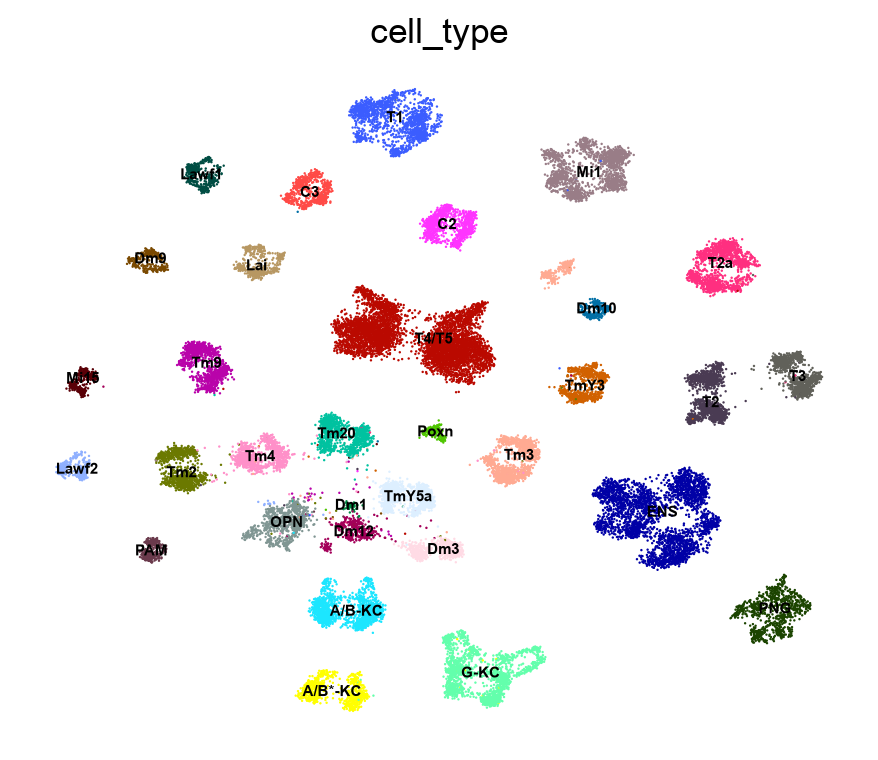

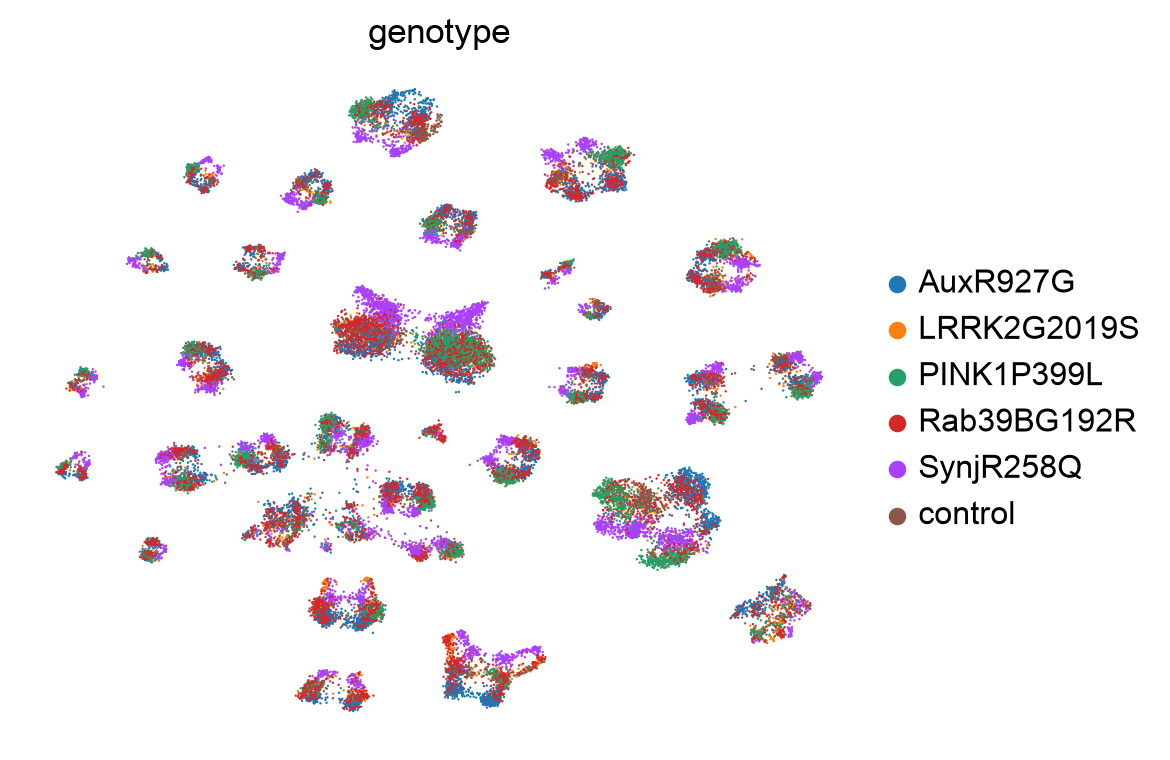

In [4]:
sc.pl.umap(adata, color="cell_type", legend_loc="on data", legend_fontsize=6)
sc.pl.umap(adata, color="genotype")

Each point is a cell and cells with similar expression sit near each other. The
clusters are the cell types. Colouring by genotype shows the mutants and the
control mixed together rather than forming separate clusters. That is what you
want: a genotype sitting apart on its own would be a sign that it had been
processed differently, and you could not then tell technical differences from
biological ones. Mixing rules out the large version of that problem, not the
small one.

You can colour the same plot by any gene, which is often the quickest way to see
what a cell type is.

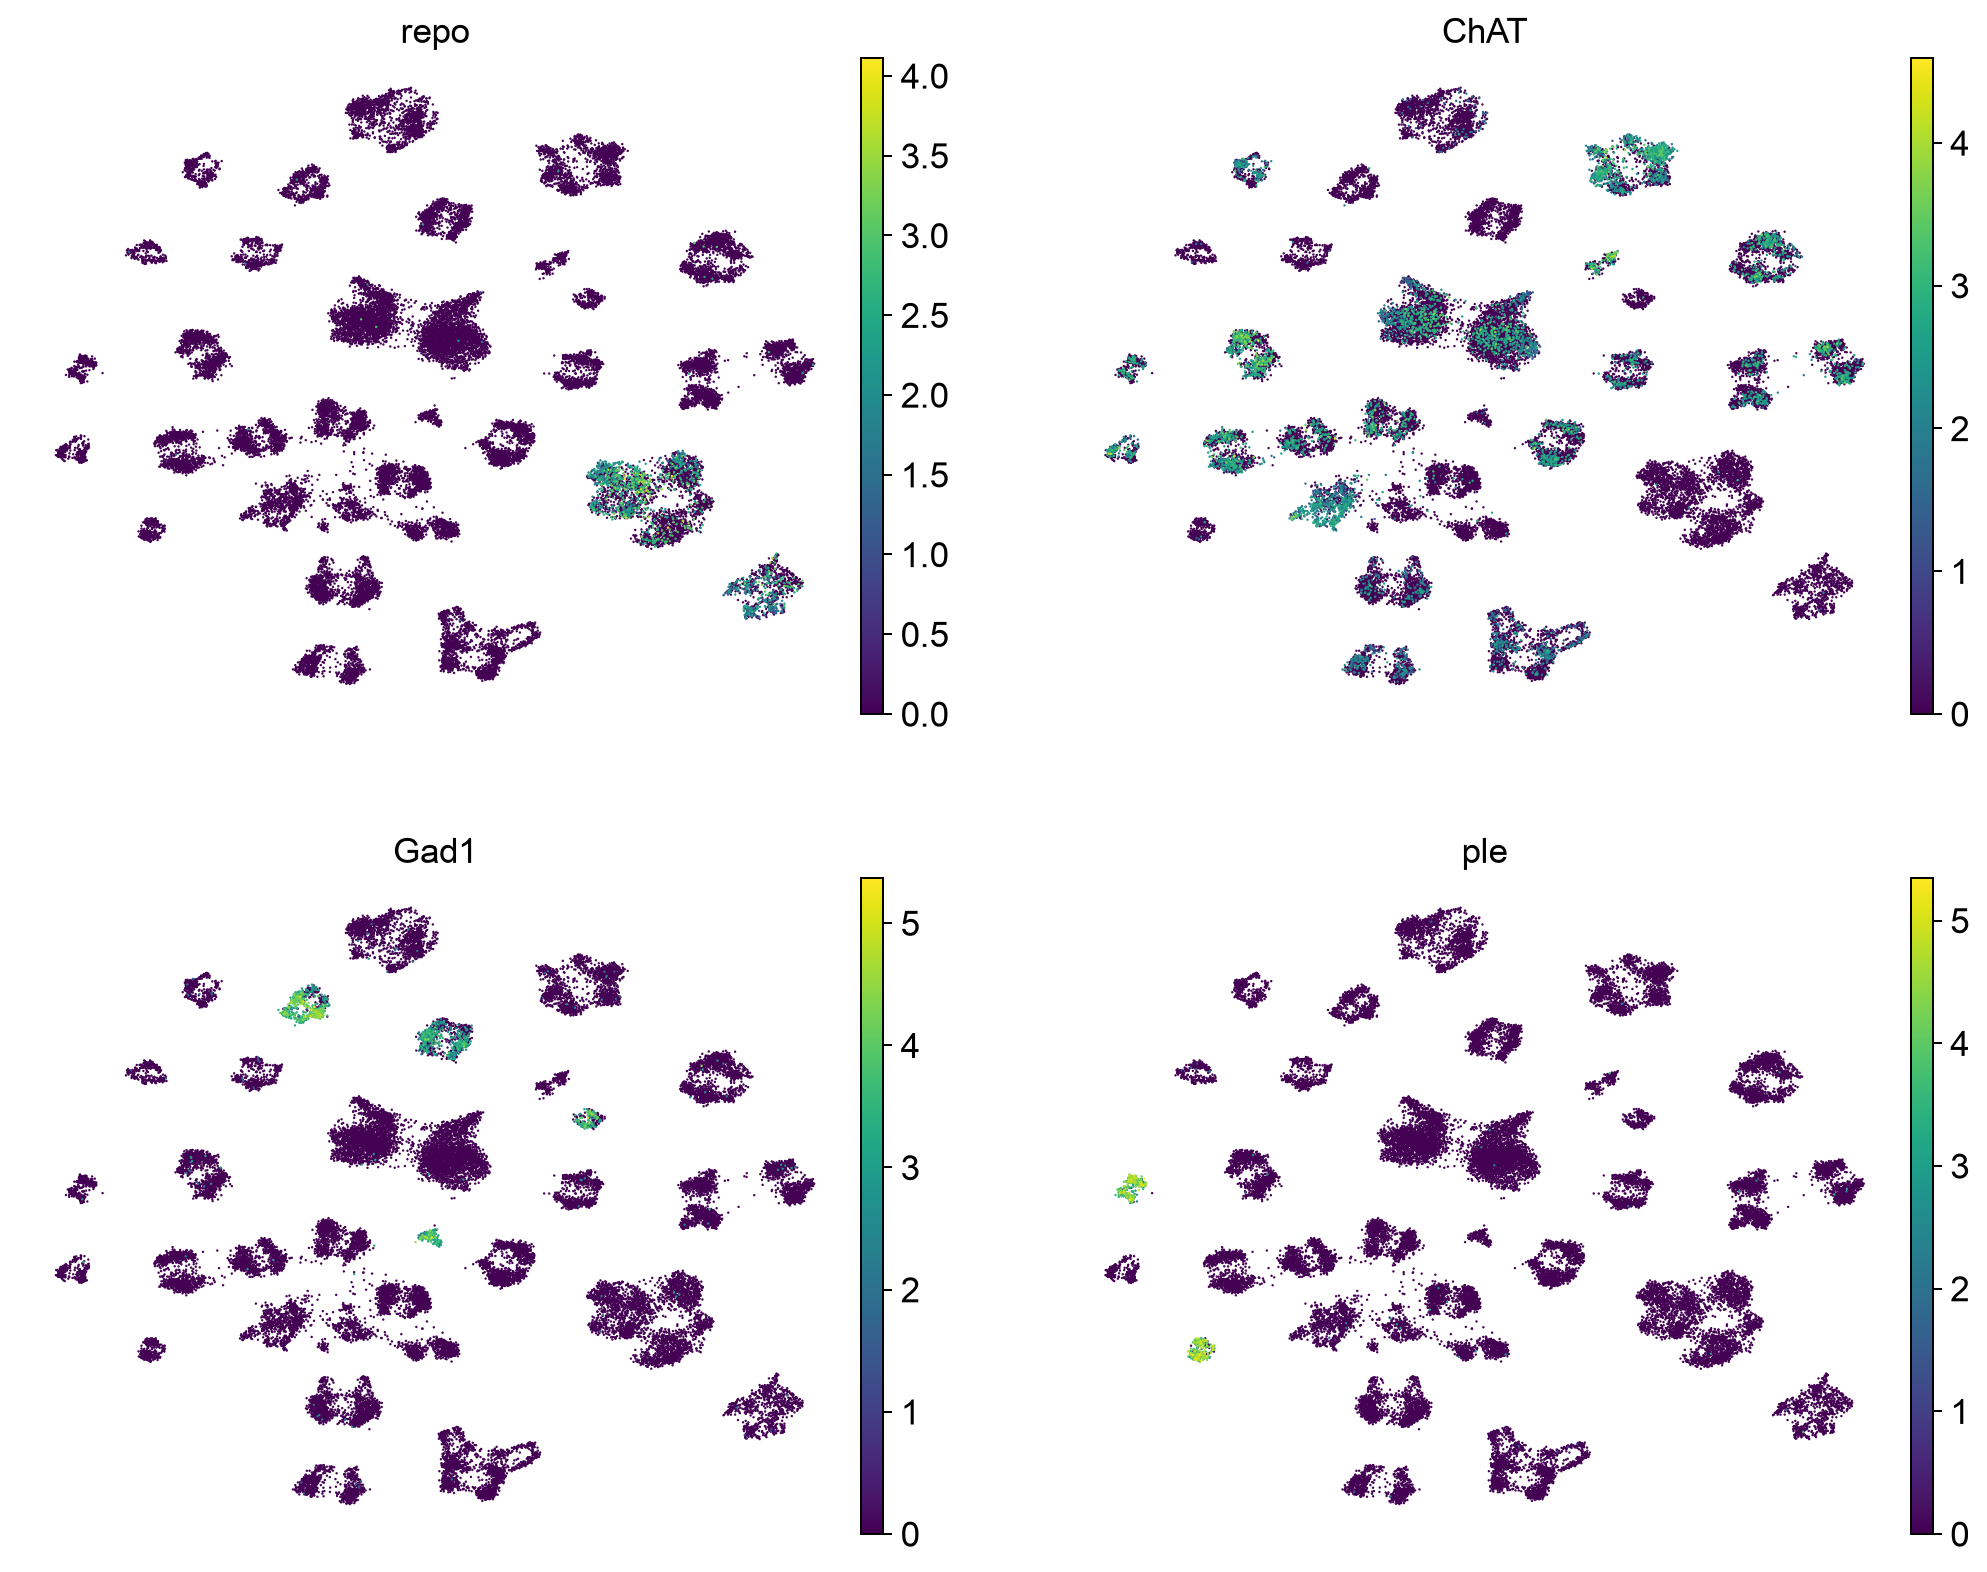

In [5]:
sc.pl.umap(adata, color=["repo", "ChAT", "Gad1", "ple"], ncols=2)

`repo` is made by glia, `ChAT` by cholinergic neurons, `Gad1` by GABAergic
neurons and `ple` by dopaminergic neurons.

The table below is the one to keep coming back to. The rows are cell types, the
columns genotypes, and the numbers are how many cells you have. A comparison with
fewer than about 50 cells on either side will not tell you much.

`margins=True` adds the totals, so the last column is how many cells each
cell type has altogether. That is the number to check before you believe a
result, and the one to divide by when you compare cell types against each other.

In [6]:
pd.crosstab(adata.obs.cell_type, adata.obs.genotype, margins=True)

genotype,AuxR927G,LRRK2G2019S,PINK1P399L,Rab39BG192R,SynjR258Q,control,All
cell_type,,,,,,,
A/B*-KC,175,124,41,153,133,152,778
A/B-KC,364,190,119,251,182,227,1333
C2,245,96,95,94,200,237,967
C3,148,69,74,62,171,174,698
Dm1,9,10,6,9,10,15,59
Dm10,65,25,19,20,31,72,232
Dm12,51,59,36,34,106,111,397
Dm3,10,101,143,51,270,90,665
Dm9,64,38,39,23,65,51,280


## The tools

One function does the main job: it takes a cell type and a mutant, and reports
which genes differ between that mutant and the control in that cell type. The
names have to match exactly, so it lists the valid ones if you mistype, and it
warns you when there are too few cells for the answer to mean anything.
`rank_genes_groups` is the same function you used in Practical 5 to find marker
genes.

In [7]:
CELL_TYPES = sorted(adata.obs.cell_type.unique())
MUTANTS = [g for g in sorted(adata.obs.genotype.unique()) if g != "control"]


def changed_genes(cell_type, mutant, n=25):
    """Genes that differ between one mutant and the control, within one cell type."""
    if cell_type not in CELL_TYPES:
        raise ValueError(f"no cell type called {cell_type!r}. Choose one of {CELL_TYPES}")
    if mutant not in MUTANTS:
        raise ValueError(f"no mutant called {mutant!r}. Choose one of {MUTANTS}")

    sub = adata[(adata.obs.cell_type == cell_type)
                & (adata.obs.genotype.isin([mutant, "control"]))].copy()

    n_mut = int((sub.obs.genotype == mutant).sum())
    n_ctl = int((sub.obs.genotype == "control").sum())
    if min(n_mut, n_ctl) < 30:
        print(f"Careful: only {n_mut} {mutant} cells and {n_ctl} control cells. "
              f"An empty result here means too few cells, not no change.")

    sc.tl.rank_genes_groups(sub, "genotype", groups=[mutant],
                            reference="control", method="wilcoxon")
    out = sc.get.rank_genes_groups_df(sub, group=mutant)
    return out[out.pvals_adj < 0.05].head(n)

Each row is a gene. `logfoldchanges` says how much it changed: +1 means twice
as much in the mutant as in the control, and -1 means half as much.
`pvals_adj` is how likely a difference that size would be by chance, already
corrected for having tested every gene at once, and the table keeps only the
rows below 0.05. The `scores` column is what the ranking was done on, and the
rows come back in that order, so the gene at the top is the most consistent
change rather than the largest one.

An empty or very short result can mean the cell type is too small rather than
unaffected. Running the same comparison on a cell type with a similar total in
the table above tells you which it is.

Three more things you will probably want. The third one is in per cent: each
column adds up to 100, so it says what share of that genotype's cells each cell
type makes up, not how many cells were collected.

In [8]:
# 1. By default changed_genes shows the top 25. Ask for more to count them all.
print("genes changed in OPN in the auxilin mutant:",
      len(changed_genes("OPN", "AuxR927G", n=5000)))

# 2. Take some genes and ask how each of the five mutants changes them, in one
#    cell type. Positive means higher in the mutant than in the control.
#    There is an example of this in use further down.
def compare_mutants(cell_type, genes):
    """Log2 fold change against the control, for each gene in every mutant."""
    out = {}
    for m in MUTANTS:
        sub = adata[(adata.obs.cell_type == cell_type)
                    & (adata.obs.genotype.isin([m, "control"]))].copy()
        sc.tl.rank_genes_groups(sub, "genotype", groups=[m],
                                reference="control", method="wilcoxon")
        d = sc.get.rank_genes_groups_df(sub, group=m).set_index("names")
        out[m] = d.logfoldchanges.reindex(genes)
    return pd.DataFrame(out).round(2)


# 3. What share of each genotype's cells is each cell type. Each column adds to
#    100, so this is about proportions rather than how many cells were collected.
share = pd.crosstab(adata.obs.cell_type, adata.obs.genotype, normalize="columns") * 100
share.loc[["OPN", "ENS", "PAM", "G-KC"]].round(2)

genes changed in OPN in the auxilin mutant: 831


genotype,AuxR927G,LRRK2G2019S,PINK1P399L,Rab39BG192R,SynjR258Q,control
cell_type,,,,,,
OPN,2.85,2.44,2.07,4.11,0.85,2.45
ENS,10.22,5.15,12.42,7.94,10.62,7.39
PAM,0.97,1.04,0.88,1.41,0.74,0.79
G-KC,7.85,5.66,1.84,6.47,4.47,4.86


Every genotype was sequenced four separate times, and `adata.obs["sample"]` says
which brain each cell came from. Putting `sample` in the table instead of
`genotype` is how you tell a real difference from one brain being unusual, and
it is worth doing before you believe any difference in proportions.

The table below is in per cent as well, this time out of each sample's cells.

In [9]:
by_sample = pd.crosstab(adata.obs.cell_type, adata.obs["sample"], normalize="columns") * 100
by_sample.loc["T4/T5"].round(2)      # a large optic lobe cell type, per sample

sample
LRRK_1_5d                     21.85
LRRK_2_5d                     18.02
LRRK_3_5d                     14.45
LRRK_4_5d                     16.86
W1118CS_5d_1                  19.69
W1118CS_5d_2                  17.38
W1118CS_5d_3                  16.88
W1118CS_5d_4                  14.25
dAux_5d_1                     10.24
dAux_5d_2                      7.42
dAux_5d_3                     11.50
dAux_5d_4                      9.96
dSynj_5d_1                    18.25
dSynj_5d_2                    18.14
dSynj_5d_3                    17.91
dSynj_5d_4                    15.77
hPINK_5d_1                    13.28
hPINK_5d_2                    17.08
hPINK_5d_3                    23.00
hPINK_5d_4                    22.38
hRAB39B_5d_1_adult_brain      24.07
hRAB39B_5d_2_central_brain     0.60
hRAB39B_5d_3_adult_brain       9.26
hRAB39B_5d_4_adult_brain      15.50
Name: T4/T5, dtype: float64

Twenty-three of the samples look alike and one does not. `hRAB39B_5d_2_central_brain`
has almost no `T4/T5`, and its name says why: it is a dissection of the central
brain, while the others are whole brains that include the optic lobes. The optic
lobe is about three quarters of the cells in every other sample and 2 per cent of
that one.

Nothing is wrong with that sample, but it is not comparable to the rest by
proportion. Because the missing cells have to be made up somewhere, everything
left in it looks enriched: it appears to contain six times the usual share of
dopaminergic neurons, which is an artefact of the dissection. If you compare
proportions, either leave that sample out or work with the other three
`Rab39B` brains.

With `sc.pl.umap(adata, color=...)` for looking at a gene across the whole brain,
that is the whole toolkit. Everything else is ordinary pandas.

If you ask for a gene that is not expressed in the cell type you chose, the fold
change comes back as something like -22 or +23. That is not a real number, it
just means the gene was zero in one of the two groups.

Avoid `sc.pl.violin` and `sc.pl.dotplot` for comparing genotypes here. Most of
these genes are detected in nearly every cell, so dot size tells you nothing, and
a violin smooths over the cells with no detected transcript in a way that makes
the distribution look bimodal when it is not. The fold changes above are clearer.

## A worked example

Here is one question answered from start to finish, so you can see the shape of
it. It is deliberately a small question.

> Auxilin recycles vesicles at the synapse. In flies carrying the auxilin
> mutation, do the olfactory projection neurons change, and is what changes to do
> with the synapse?

`OPN` is the olfactory projection neurons, which carry smell from the antennal
lobe into the brain. Start by asking which genes differ.

In [10]:
changed_genes("OPN", "AuxR927G")

,names,scores,logfoldchanges,pvals,pvals_adj
0,sif,12.923166,2.983113,3.331443e-38,1.534130e-34
1,Ubi-p5E,10.181030,1.589963,2.409962e-24,1.707366e-21
2,pum,8.566342,0.900492,1.068237e-17,2.483926e-15
3,Syp,8.102332,1.262976,5.391539e-16,1.034502e-13
4,CASK,7.936898,1.070061,2.073008e-15,3.471346e-13
5,ox,7.928966,1.025866,2.209781e-15,3.634301e-13
6,Snap25,7.868344,1.175760,3.593653e-15,5.806587e-13
7,Alk,7.677414,1.331279,1.623314e-14,2.411406e-12
8,futsch,7.518779,0.714722,5.529030e-14,7.834211e-12
9,RpL8,7.198107,0.976158,6.105407e-13,7.028850e-11


Several of those are worth looking up. `Snap25`, `CASK`, `Nrx-1` and `Syt7` are
all parts of the machinery a neuron uses to release neurotransmitter, which does
fit a broken vesicle-recycling protein.

But a list of names is not an answer yet, because those genes might change in
every cell type. Checking a second cell type is what turns it into one.

In [11]:
a = changed_genes("OPN", "AuxR927G")
b = changed_genes("G-KC", "AuxR927G")      # gamma Kenyon cells, for comparison

print("only in OPN :", sorted(set(a.names) - set(b.names))[:10])
print("in both     :", sorted(set(a.names) & set(b.names))[:10])

only in OPN : ['Alk', 'CG12605', 'CG6770', 'GABA-B-R1', 'Galphao', 'Glut1', 'RpL8', 'Snap25', 'Syp', 'Syt7']
in both     : ['CASK', 'CG40178', 'Liprin-gamma', 'Nrx-1', 'Ubi-p5E', 'Vha16-1', 'futsch', 'mt:CoIII', 'sif']


Some genes change in both and some only in the olfactory neurons, so the response
is partly general and partly specific to that cell type.

Finally, whether the other four mutants change the same genes. The first column
is red by construction, because the genes were chosen as the ones auxilin changes
most. What matters is what the other four columns do to them.

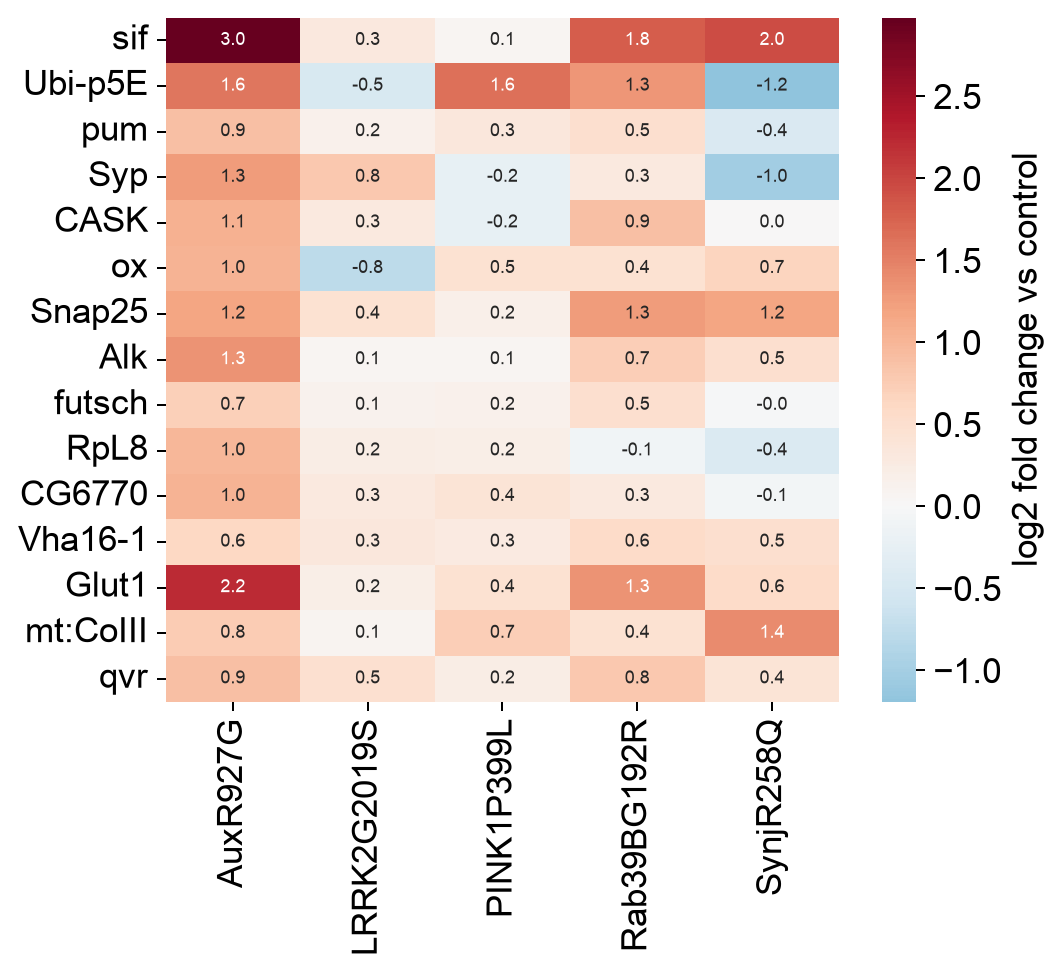

In [12]:
genes = list(changed_genes("OPN", "AuxR927G", n=15).names)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(compare_mutants("OPN", genes), cmap="RdBu_r", center=0,
            annot=True, fmt=".1f", annot_kws={"size": 7},
            cbar_kws={"label": "log2 fold change vs control"}, ax=ax)
ax.set_ylabel("")
ax.grid(False)
plt.show()

**The answer.** In flies with the auxilin mutation, olfactory projection neurons
change the expression of genes for releasing neurotransmitter. Part of that
response is shared with Kenyon cells and part is not, and `Snap25` turns out to
be expressed across most neurons rather than being specific to this cell type.

That is a complete small finding: a question, the analysis, and an answer that
says what it does and does not show. Yours should look like that.

## Your question

Choose something you want to know and answer it. Anything you can ask with the
tools above is fair. If you would rather start from a suggestion:

- Does any of the five mutants affect the dopaminergic neurons, `PAM`? These are
  the cells the disease eventually kills.
- Auxilin and synaptojanin both work at the synapse. Do they break the same
  things?
- Which cell type changes most in the mutant you find most interesting, and is
  that just because it has the most cells?
- Are glia affected differently from neurons? Two of the 32 cell types are glia:
  `PNG`, the glia that wrap the outside of the brain, and `ENS`, the glia inside
  it. Everything else here is a neuron.
- Is any cell type becoming rarer in a mutant, which would suggest cells are
  already being lost? Check this one across the four samples per genotype before
  you believe it.
- Pick a gene you already work on and ask where in the brain it changes.
  `sc.pl.umap(adata, color="your gene")` shows which cells express it, and
  `compare_mutants` shows what each of the five does to it. Not every gene you
  know from another animal has a fly counterpart.
- `LRRK2` is the commonest genetic cause of Parkinson's, but `LRRK2G2019S`
  changes the fewest genes of the five mutants. What could explain that?

Write your analysis below. Add as many cells as you need.

In [13]:
# your analysis

## What to present

Three slides.

1. Your question, and why you chose it.
2. What you did and what you found, with one figure.
3. What your result does not show, and what you would do next.

One thing worth knowing before you start: ribosomal genes, mitochondrial
transcripts and histone genes appear near the top of a lot of comparisons for
technical reasons rather than biological ones. If your gene list is mostly those,
say so. That is a useful finding about the experiment and better than presenting
it as biology.